# Repeat Purchase Prediction, part 3
# Modelling

## Notebook purpose

This notebook starts from the cleaned data and the two pipelines built in `02_preprocessing.ipynb`. It tunes both, picks one, checks it once on the holdout and writes the Kaggle submission. It covers the modelling part of the homework. Other model families may be tried later for the final project, in a separate notebook.

## Approach

- **Same validation as before:** four expanding yearly folds (2020 to 2023) with a 90-day gap, and the holdout from 2024 left untouched until the final check.
- **Same decision rule:** F1 at each model's own threshold, a customer-level bootstrap of the F1 difference, and a fold-consistency check.
- **Tuning with Optuna.** A search can be steered either by log-loss or by F1, and every trial records both, so the two ways of steering can be compared.
- **Shared code lives in `src/`:** the cleaning and the pipelines in `repeat_purchase_prep.py`, the scoring and the decision rule in `evaluation.py`.

## Planned structure

1. **Setup and data**
2. **Starting point:** the two untuned pipelines
3. **Tuning setup**
4. **Logistic regression**
5. **Gradient boosting**
6. **Threshold and model choice**
7. **Holdout assessment**
8. **Final model and submission**
9. **Summary**

# 1. Setup and data

In [12]:
# Handle file paths without relying on computer-specific locations.
from pathlib import Path

# Locate the project from the current folder or one of its parent folders.
PROJECT_ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "data").is_dir()
        and (folder / "notebooks").is_dir()
    ),
    None,
)

# Give a clear error if the expected project structure cannot be found.
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate the project. Open the notebook within the repository."
    )

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"                  # original files, never modified
PROCESSED_DIR = DATA_DIR / "preprocessed"   # outputs of 02_preprocessing
SUBMISSION_DIR = DATA_DIR / "submissions"   # Kaggle files written by this notebook
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

# The files this notebook needs from earlier steps
NEEDED = [
    PROCESSED_DIR / "train_clean.parquet",
    PROCESSED_DIR / "test_clean.parquet",
    PROCESSED_DIR / "decision_log.json",
    PROCESSED_DIR / "column_roles.json",
    RAW_DIR / "sample_submission.csv",
]
for path in NEEDED:
    if not path.is_file():
        raise FileNotFoundError(f"Missing file: {path}. Run 02_preprocessing.ipynb first.")
print("All input files found.")

All input files found.


## 1.1. Imports and display settings

In [13]:
# Standard library
import sys
import json

# Data and numbers
import pandas as pd
import numpy as np

# Charts
import matplotlib.pyplot as plt
import seaborn as sns

# Notebook display
from IPython.display import display

# Hyperparameter search
import optuna

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel

# Metrics
from sklearn.metrics import f1_score, log_loss, roc_auc_score

# Project code in <project>/src
sys.path.insert(0, str(PROJECT_ROOT))
import src.repeat_purchase_prep as rpp
import src.evaluation as ev
import src.tuning as tn
from src.decision_log import DecisionLog

# Constants shared with 02_preprocessing
RANDOM_STATE = rpp.RANDOM_STATE
target = rpp.TARGET

# Display settings
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", "{:,.3f}".format)

# Plot style
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

# Optuna prints one line per trial by default; keep only warnings
optuna.logging.set_verbosity(optuna.logging.WARNING)

## 1.2. Data, folds and decision log

The cleaned files already contain every stateless repair from `02_preprocessing.ipynb`, so nothing is cleaned again here. The development set, the holdout and the four folds are rebuilt with the same functions, and the column roles are checked against the ones saved there, so both notebooks work on exactly the same inputs.

The decision log is loaded and continued, so every modelling choice ends up in the same record as the preprocessing ones.

In [14]:
train = pd.read_parquet(PROCESSED_DIR / "train_clean.parquet")
test = pd.read_parquet(PROCESSED_DIR / "test_clean.parquet")
sample_submission = pd.read_csv(RAW_DIR / "sample_submission.csv")

# Same splits and folds as in 02_preprocessing
dev, holdout = rpp.split_dev_holdout(train)
folds = rpp.year_folds(dev["purchase_date"])

# Same column roles as the ones saved by 02_preprocessing
roles = rpp.column_roles(dev)
saved_roles = json.loads((PROCESSED_DIR / "column_roles.json").read_text(encoding="utf-8"))
assert roles == saved_roles, "Column roles differ from 02_preprocessing"

# Continue the decision log from where preprocessing stopped
log = DecisionLog.load(PROCESSED_DIR / "decision_log.json")

print(f"Train: {train.shape} | Test: {test.shape}")
print(f"Development: {len(dev):,} rows | Holdout: {len(holdout):,} rows | Folds: {len(folds)}")
print(f"Decisions logged so far: {len(log)} (last: {log.items[-1].step})")

Train: (6469, 53) | Test: (986, 52)
Development: 5,403 rows | Holdout: 835 rows | Folds: 4
Decisions logged so far: 32 (last: D30)


# 2. Starting point

The two pipelines from `02_preprocessing.ipynb` are scored with their default settings, so every tuned version below has something to be compared with. Training log-loss is reported next to validation log-loss: a model that does much better on the rows it learned from than on later rows is overfitting.

In [15]:
start_pipes = {
    "logistic": (
        rpp.build_linear_pipeline(LogisticRegression(max_iter=5000), roles),
        rpp.pipeline_inputs(roles, "linear"),
    ),
    "hist_gb": (
        rpp.build_tree_pipeline(HistGradientBoostingClassifier(random_state=RANDOM_STATE), roles),
        rpp.pipeline_inputs(roles, "tree"),
    ),
}

start_runs = {}
for name, (pipe, inputs) in start_pipes.items():
    start_runs[name] = ev.score_folds(pipe, dev, folds, inputs, train_scores=True)

start_summary = pd.DataFrame({name: ev.summary_row(*run) for name, run in start_runs.items()}).T
display(start_summary)

,n_features,f1_stacked,f1_floor,log_loss,roc_auc,threshold,train_log_loss,overfit_gap
logistic,20.000,0.750,0.709,0.561,0.784,0.340,0.552,0.009
hist_gb,38.000,0.732,0.709,0.607,0.760,0.315,0.259,0.348


Both pipelines reproduce the scores from `02_preprocessing.ipynb`: F1 0.750 for logistic regression and 0.732 for gradient boosting, against an all-positive floor of 0.709.

The training log-loss tells two different stories. Logistic regression does almost as well on later years as on the rows it learned from, with a gap of 0.009, so it is not overfitting and tuning can only refine it. Gradient boosting reaches 0.259 on its training rows but 0.607 on later years, a gap of 0.348. It has largely memorised the rows it was fitted on. That points to where tuning matters most: settings that make the trees more cautious, such as more rows per leaf, fewer leaves, a penalty on leaf values and a slower learning rate.

# 3. Tuning setup

Tuning tries many settings for each model and keeps the best. Three choices shape how that is done here.

- **Preprocessing is fitted once per fold.** Only the model's settings change between trials, so the fill values, encoders and scaling are the same for every trial. Fitting them once per fold and reusing the result saves most of the work, an idea taken from the week 5 notebook. For logistic regression there are two versions, with and without the log transform from section 5.4 of `02_preprocessing.ipynb`, since that one is a setting to tune.
- **Optuna chooses the settings.** Instead of trying every combination on a grid, it learns from earlier trials which regions look promising and spends more trials there.
- **The search can be steered by log-loss or by F1.** Log-loss is smooth and uses every prediction, while F1 is the competition metric but jumps when a few rows cross the threshold. Each model is searched both ways with the same seed, and every trial records both metrics, so the two ways of steering can be compared directly. Whichever steers, the final choice between the best trials is made with the usual decision rule on F1.

Before any search, a check: the cached matrices with the default settings must reproduce the starting point exactly.

In [16]:
# Linear branch: two caches, with and without log1p on the skewed columns
log_cols = rpp.skewed_columns(dev, roles["num"])
linear_inputs = rpp.pipeline_inputs(roles, "linear")
linear_cache = {
    use_log: tn.FoldCache(
        rpp.build_linear_pipeline(LogisticRegression(), roles, log1p_cols=log_cols if use_log else None)
        .named_steps["prep"],
        dev, folds, linear_inputs,
    )
    for use_log in (False, True)
}

# Tree branch: one cache; small categories come first in its matrix
tree_inputs = rpp.pipeline_inputs(roles, "tree")
tree_cache = tn.FoldCache(
    rpp.build_tree_pipeline(HistGradientBoostingClassifier(), roles).named_steps["prep"],
    dev, folds, tree_inputs,
)
n_tree_cats = len([c for c in roles["low"] if c not in rpp.COARSE_DROP])

print(f"log1p candidates: {len(log_cols)} columns")
print(f"Linear matrix: {linear_cache[False].folds[-1]['X_train'].shape[1]} columns before selection")
print(f"Tree matrix: {tree_cache.folds[-1]['X_train'].shape[1]} columns, first {n_tree_cats} categorical")

log1p candidates: 27 columns
Linear matrix: 75 columns before selection
Tree matrix: 38 columns, first 7 categorical


In [17]:
# Default settings on the cached matrices must give the same scores as section 2
default_linear = Pipeline([
    ("select", SelectFromModel(LogisticRegression(
        l1_ratio=0.5, solver="saga", C=rpp.ENET_C, max_iter=5000, random_state=RANDOM_STATE))),
    ("model", LogisticRegression(max_iter=5000)),
])
default_tree = HistGradientBoostingClassifier(
    categorical_features=list(range(n_tree_cats)), random_state=RANDOM_STATE,
)

cached_runs = {
    "logistic": tn.evaluate_cached(linear_cache[False], default_linear),
    "hist_gb": tn.evaluate_cached(tree_cache, default_tree),
}
check = pd.DataFrame({
    f"{name} ({source})": ev.summary_row(*run)
    for name in ("logistic", "hist_gb")
    for source, run in [("base", start_runs[name]), ("cached", cached_runs[name])]
}).T
display(check[["n_features", "f1_stacked", "log_loss", "roc_auc", "threshold", "overfit_gap"]])

,n_features,f1_stacked,log_loss,roc_auc,threshold,overfit_gap
logistic (base),20.000,0.750,0.561,0.784,0.340,0.009
logistic (cached),20.000,0.750,0.561,0.784,0.340,0.009
hist_gb (base),38.000,0.732,0.607,0.760,0.315,0.348
hist_gb (cached),38.000,0.732,0.607,0.760,0.315,0.348


The cached matrices reproduce the starting point exactly, for both models, so the searches below run on the same inputs as every earlier comparison. The linear matrix has 75 columns before elastic net selects about 20 of them, and the tree matrix has 38, the first seven of them categorical.

# 4. Logistic regression

Four settings are tuned:

- **use_log:** whether the skewed columns are log-transformed first. It improved log-loss in section 5.4 of `02_preprocessing.ipynb` but not F1.
- **select_C:** how strongly elastic net selects columns. Smaller values keep fewer columns. Section 7.7 showed the F1 gain depended on it.
- **l1_ratio:** the mix in the selector, from close to ridge (0.1, keeps groups of related columns) to close to lasso (0.9, keeps one per group).
- **model_C:** the penalty on the final logistic regression. Smaller values pull the coefficients towards zero.

The search runs twice with the same seed and 60 trials each: once steered by log-loss and once by F1.

The choice is fixed before looking at the results. The five best trials of each search are compared with the untuned pipeline using the usual rule. If none is clearly better, the untuned pipeline stays. If several are, they are compared with the best of them in the same way, and among those not clearly worse the one with the fewest columns is chosen.

In [18]:
import warnings
from sklearn.exceptions import ConvergenceWarning

# saga can stop a little short of full convergence at some settings; the fold scores show the effect anyway
warnings.filterwarnings("ignore", category=ConvergenceWarning)


def suggest_linear(trial):
    """Settings tried for the linear branch."""
    return {
        "use_log": trial.suggest_categorical("use_log", [False, True]),
        "select_C": trial.suggest_float("select_C", 0.03, 0.5, log=True),
        "l1_ratio": trial.suggest_float("l1_ratio", 0.1, 0.9),
        "model_C": trial.suggest_float("model_C", 1e-3, 100, log=True),
    }


def get_linear_cache(params):
    return linear_cache[bool(params["use_log"])]


def make_linear(params):
    """Elastic-net selection, then logistic regression, on the cached linear matrix."""
    return Pipeline([
        ("select", SelectFromModel(LogisticRegression(
            l1_ratio=params["l1_ratio"], solver="saga", C=params["select_C"],
            max_iter=5000, random_state=RANDOM_STATE,
        ))),
        ("model", LogisticRegression(C=params["model_C"], max_iter=5000)),
    ])

In [19]:
study_lin = {
    "log_loss": tn.tune(get_linear_cache, make_linear, suggest_linear,
                        objective="log_loss", n_trials=60, name="logistic_log_loss"),
    "f1": tn.tune(get_linear_cache, make_linear, suggest_linear,
                  objective="f1", n_trials=60, name="logistic_f1"),
}

# Five best trials of each search, with every recorded metric
show = ["use_log", "select_C", "l1_ratio", "model_C", "n_features",
        "log_loss", "f1", "threshold", "roc_auc", "overfit_gap"]
for objective, study in study_lin.items():
    print(f"\nSteered by {objective}")
    display(tn.trials_table(study).head(5)[show])

  0%|          | 0/60 [00:00<?, ?it/s]

  0%|          | 0/60 [00:00<?, ?it/s]


Steered by log_loss


,use_log,select_C,l1_ratio,model_C,n_features,log_loss,f1,threshold,roc_auc,overfit_gap
trial,,,,,,,,,,
42,True,0.033,0.655,0.010,14.500,0.549,0.742,0.350,0.781,-0.002
45,True,0.033,0.637,0.010,14.500,0.549,0.742,0.350,0.781,-0.003
47,True,0.033,0.635,0.015,14.500,0.549,0.744,0.385,0.781,-0.001
23,True,0.041,0.688,0.012,15.000,0.549,0.743,0.340,0.782,-0.001
33,True,0.040,0.860,0.012,13.750,0.549,0.742,0.360,0.781,-0.002



Steered by f1


,use_log,select_C,l1_ratio,model_C,n_features,log_loss,f1,threshold,roc_auc,overfit_gap
trial,,,,,,,,,,
41,False,0.058,0.102,0.096,23.500,0.560,0.753,0.335,0.783,0.007
51,False,0.035,0.105,0.053,23.750,0.560,0.753,0.325,0.783,0.006
28,False,0.046,0.143,0.026,23.750,0.559,0.753,0.330,0.782,0.003
49,False,0.036,0.108,0.080,23.750,0.561,0.752,0.325,0.783,0.007
34,False,0.064,0.158,0.127,23.500,0.560,0.752,0.340,0.783,0.008


The charts below show how each search progressed, which settings mattered most, and how log-loss and F1 relate across all trials.

In [20]:
from optuna.visualization import (
    plot_optimization_history, plot_param_importances, plot_slice,
)

for objective, study in study_lin.items():
    plot_optimization_history(study).update_layout(title=f"Logistic regression, steered by {objective}").show()
    plot_param_importances(study).update_layout(title=f"Which settings mattered, steered by {objective}").show()

# How log-loss moves with each setting (log-loss search)
plot_slice(study_lin["log_loss"]).update_layout(title="Log-loss against each setting").show()

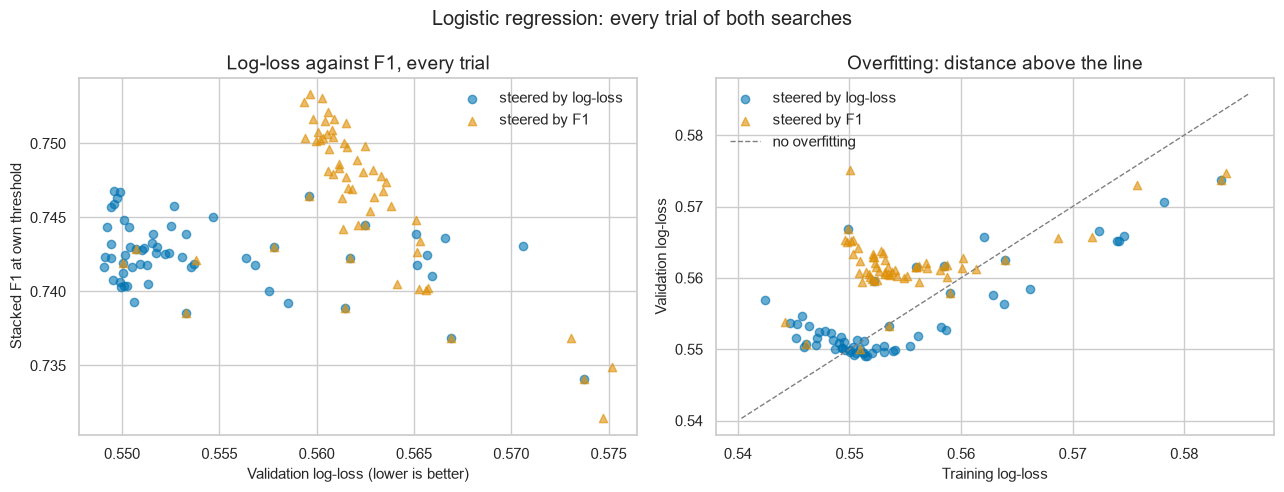

In [21]:
fig = tn.plot_trials(
    {"steered by log-loss": study_lin["log_loss"], "steered by F1": study_lin["f1"]},
    title="Logistic regression: every trial of both searches",
)
plt.show()

The five best trials of each search are re-scored and compared with the untuned pipeline using the decision rule.

In [ ]:
# Top 5 of each search, named by search and trial number
candidates = {}
for objective, study in study_lin.items():
    candidates.update(tn.rescore(tn.top_params(study, 5), get_linear_cache, make_linear,
                                 prefix=f"{objective}_trial_"))

runs_lin = {"base": start_runs["logistic"], **candidates}
table_lin = ev.judge(runs_lin, "base")
display(table_lin)

# Among the clear winners: compare with the best of them, ties go to fewer columns
better = table_lin.index[table_lin["verdict"] == "better"].tolist()
if not better:
    chosen_tree = "base"
    print("No trial is clearly better than the untuned pipeline: base stays.")
else:
    best_name = table_lin.loc[better, "f1_stacked"].idxmax()
    table_better = ev.judge({name: runs_lin[name] for name in better}, best_name, tie_rule=True)
    display(table_better)
    equally_good = table_better.index[table_better["verdict"].isin(["reference", "tie, fewer columns", "no clear difference"])]
    # Fewest columns first; if those are equal, the best F1
    chosen_tree = (table_better.loc[equally_good]
                   .sort_values(["n_features", "f1_stacked"], ascending=[True, False])
                   .index[0])
    print(f"Chosen: {chosen_tree}")

,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,20.000,0.750,0.000,NaN,NaN,0,0.340,0.561,0.128,0.784,reference
log_loss_trial_42,14.500,0.742,-0.009,-0.020,0.002,3,0.350,0.549,0.140,0.781,no clear difference
log_loss_trial_45,14.500,0.742,-0.008,-0.019,0.003,3,0.350,0.549,0.140,0.781,no clear difference
log_loss_trial_47,14.500,0.744,-0.006,-0.018,0.005,2,0.385,0.549,0.140,0.781,no clear difference
log_loss_trial_23,15.000,0.743,-0.007,-0.018,0.004,3,0.340,0.549,0.139,0.782,no clear difference
log_loss_trial_33,13.750,0.742,-0.008,-0.020,0.003,3,0.360,0.549,0.139,0.781,no clear difference
f1_trial_41,23.500,0.753,0.003,-0.003,0.010,1,0.335,0.560,0.129,0.783,no clear difference
f1_trial_51,23.750,0.753,0.003,-0.004,0.012,2,0.325,0.560,0.129,0.783,no clear difference
f1_trial_28,23.750,0.753,0.002,-0.006,0.013,2,0.330,0.559,0.129,0.782,no clear difference


No trial is clearly better than the untuned pipeline: base stays.


Tuning does not clearly improve logistic regression on F1, so the untuned pipeline is kept.

Steered by log-loss, the search finds better probabilities. Log-loss drops from 0.561 to 0.549, and the best trials agree on the recipe: the log transform switched on and a strong penalty on the final model. Their F1 is between 0.742 and 0.744, slightly below the untuned 0.750, though not clearly so. The stronger penalty makes the probabilities more modest and better calibrated, while the ranking of customers gets a little blurrier, with ROC-AUC 0.781 to 0.782 against 0.784. It also brings training and validation log-loss together, closing the small gap seen in section 2.

Steered by F1, the best trials reach 0.752 to 0.753, up to 0.003 above the untuned pipeline. Every bootstrap interval includes zero, though, and a gap of this size is what picking the best of 60 noisy tries produces even when the settings make no real difference. Two further signs point to noise: the settings the F1 search rated as most important changed completely between a first run of 20 trials and the full run of 60, and 0.003 of F1 amounts to one or two test predictions changing side. The five best F1 trials do sit in the same region of settings, so a very small real gain cannot be ruled out, but the data cannot confirm it.

The two searches reward different things. Steered by log-loss, the penalty on the final model explains most of the variation, since it sets how confident the probabilities are. Steered by F1, the ranking near the threshold matters, and that surface is too noisy to point anywhere stable.

The better-calibrated version is not adopted, but it may still be useful later, for example if the probabilities of two models are averaged, where calibration matters more than the exact ranking.

In [23]:
log.record(
    "D31", "logistic regression settings", "keep the untuned pipeline (elastic net C = 0.1, model C = 1, no log1p)",
    "No tuned trial clearly better on F1 (60 trials per search). Log-loss steering improved log-loss "
    "(0.561 -> 0.549: log1p on, strong model penalty) but F1 fell to 0.742-0.744; F1 steering reached "
    "0.752-0.753 (+0.003, intervals include zero, consistent with best-of-60 optimism).",
    0, 0,
    carries={"chosen": "base", "best_log_loss_params": tn.top_params(study_lin["log_loss"], 1),
             "best_f1_params": tn.top_params(study_lin["f1"], 1)},
)
display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
32,D31,logistic regression settings,"keep the untuned pipeline (elastic net C = 0.1, model C = 1, no log1p)",No tuned trial clearly better on F1 (60 trials per search). Log-loss steering improved log-loss ...,0,0


# 5. Gradient boosting

Section 2 showed that gradient boosting with its default settings learns its training rows far better than later years, with a gap of 0.348 in log-loss. The settings tuned here all make the trees more cautious, in different ways:

- **learning_rate** and **max_iter:** how much each new tree corrects the previous ones, and how many trees there are. Smaller steps with more trees usually generalise better.
- **max_leaf_nodes:** how large each tree can grow. Smaller trees capture simpler patterns.
- **min_samples_leaf:** how many rows each leaf needs. Larger values stop the model from building rules for a handful of purchases.
- **l2_regularization:** a penalty that pulls extreme leaf values back towards zero.
- **max_features:** the share of columns each split may consider, which adds some randomness and makes the trees less alike.

Early stopping is left off, because it sets aside a random share of the training rows to decide when to stop, which would mix time periods inside a fold.

The search runs twice with the same seed and 60 trials each, once steered by log-loss and once by F1. The winner is chosen as for logistic regression: the five best trials of each search are compared with the untuned pipeline; if none is clearly better, the untuned pipeline stays; if several are, the one with the fewest columns among those not clearly worse than the best is chosen. Every trial here uses the same 38 columns, so in practice that tie goes to the trial with the best F1.

In [24]:
def suggest_tree(trial):
    """Settings tried for the tree branch: all of them make the trees more or less cautious."""
    return {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_iter": trial.suggest_int("max_iter", 50, 800, log=True),
        "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 4, 64, log=True),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 10, 300, log=True),
        "l2_regularization": trial.suggest_float("l2_regularization", 1e-3, 30, log=True),
        "max_features": trial.suggest_float("max_features", 0.3, 1.0),
    }


def get_tree_cache(params):
    return tree_cache  # the tree preprocessing has no tuned settings


def make_tree(params):
    """Gradient boosting on the cached tree matrix (small categories first)."""
    return HistGradientBoostingClassifier(
        **params,
        categorical_features=list(range(n_tree_cats)),
        early_stopping=False,  
        random_state=RANDOM_STATE,
    )

In [25]:
study_tree = {
    "log_loss": tn.tune(get_tree_cache, make_tree, suggest_tree,
                        objective="log_loss", n_trials=60, name="hist_gb_log_loss"),
    "f1": tn.tune(get_tree_cache, make_tree, suggest_tree,
                  objective="f1", n_trials=60, name="hist_gb_f1"),
}

show_tree = ["learning_rate", "max_iter", "max_leaf_nodes", "min_samples_leaf",
             "l2_regularization", "max_features", "log_loss", "f1", "threshold",
             "roc_auc", "train_log_loss", "overfit_gap"]
for objective, study in study_tree.items():
    print(f"\nSteered by {objective}")
    display(tn.trials_table(study).head(5)[show_tree])

  0%|          | 0/60 [00:00<?, ?it/s]

  0%|          | 0/60 [00:00<?, ?it/s]


Steered by log_loss


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,max_features,log_loss,f1,threshold,roc_auc,train_log_loss,overfit_gap
trial,,,,,,,,,,,,
35,0.016,393,7,228,0.045,0.806,0.545,0.750,0.370,0.786,0.504,0.041
50,0.018,394,5,114,0.001,0.508,0.545,0.748,0.370,0.786,0.515,0.030
59,0.019,386,4,112,0.001,0.532,0.546,0.748,0.365,0.786,0.524,0.022
20,0.019,382,5,108,0.008,0.709,0.546,0.748,0.360,0.785,0.513,0.034
26,0.019,415,6,90,0.004,0.548,0.546,0.749,0.375,0.786,0.500,0.046



Steered by f1


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,max_features,log_loss,f1,threshold,roc_auc,train_log_loss,overfit_gap
trial,,,,,,,,,,,,
32,0.025,52,17,29,0.013,0.324,0.570,0.755,0.450,0.787,0.540,0.030
52,0.015,67,14,23,0.008,0.355,0.584,0.754,0.460,0.785,0.563,0.021
59,0.026,65,23,32,0.004,0.372,0.559,0.754,0.420,0.787,0.506,0.053
17,0.018,57,25,29,0.003,0.497,0.579,0.753,0.455,0.782,0.538,0.041
44,0.026,59,23,30,0.006,0.412,0.563,0.753,0.425,0.784,0.513,0.050


The charts show how each search progressed, which settings mattered, and whether the tuned trees still overfit.

In [26]:
for objective, study in study_tree.items():
    plot_optimization_history(study).update_layout(title=f"Gradient boosting, steered by {objective}").show()
    plot_param_importances(study).update_layout(title=f"Which settings mattered, steered by {objective}").show()

plot_slice(study_tree["log_loss"]).update_layout(title="Log-loss against each setting").show()

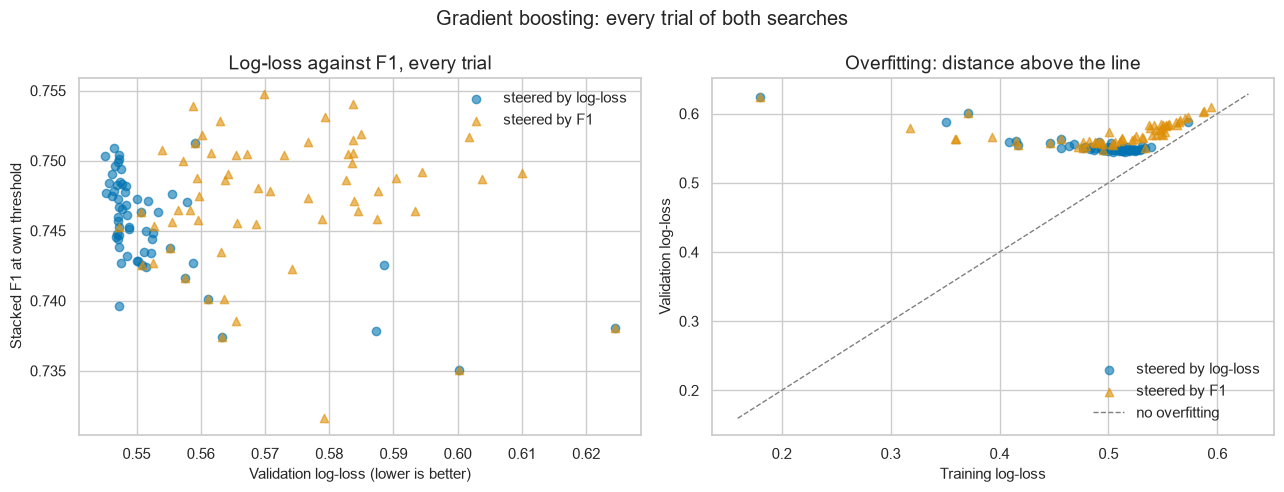

In [27]:
fig = tn.plot_trials(
    {"steered by log-loss": study_tree["log_loss"], "steered by F1": study_tree["f1"]},
    title="Gradient boosting: every trial of both searches",
)
plt.show()

The five best trials of each search are re-scored and compared with the untuned pipeline using the decision rule.

In [ ]:
candidates = {}
for objective, study in study_tree.items():
    candidates.update(tn.rescore(tn.top_params(study, 5), get_tree_cache, make_tree,
                                 prefix=f"{objective}_trial_"))

runs_tree = {"base": start_runs["hist_gb"], **candidates}
table_tree = ev.judge(runs_tree, "base")
display(table_tree)

# Among the clear winners: compare with the best of them, ties go to fewer columns (equal here, so best F1)
better = table_tree.index[table_tree["verdict"] == "better"].tolist()
if not better:
    chosen_tree = "base"
    print("No trial is clearly better than the untuned pipeline: base stays.")
else:
    best_name = table_tree.loc[better, "f1_stacked"].idxmax()
    table_better = ev.judge({name: runs_tree[name] for name in better}, best_name, tie_rule=True)
    display(table_better)
    equally_good = table_better.index[table_better["verdict"].isin(["reference", "tie, fewer columns", "no clear difference"])]
    # Fewest columns first; if those are equal, the best F1
    chosen_tree = (table_better.loc[equally_good]
                   .sort_values(["n_features", "f1_stacked"], ascending=[True, False])
                   .index[0])
    print(f"Chosen: {chosen_tree}")

,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,38.000,0.732,0.000,NaN,NaN,0,0.315,0.607,0.082,0.760,reference
log_loss_trial_35,38.000,0.750,0.019,0.006,0.033,0,0.370,0.545,0.144,0.786,better
log_loss_trial_50,38.000,0.748,0.016,0.003,0.031,0,0.370,0.545,0.144,0.786,better
log_loss_trial_59,38.000,0.748,0.017,0.003,0.032,0,0.365,0.546,0.143,0.786,better
log_loss_trial_20,38.000,0.748,0.016,0.003,0.031,0,0.360,0.546,0.143,0.785,better
log_loss_trial_26,38.000,0.749,0.018,0.006,0.032,0,0.375,0.546,0.143,0.786,better
f1_trial_32,38.000,0.755,0.023,0.009,0.039,0,0.450,0.570,0.119,0.787,better
f1_trial_52,38.000,0.754,0.023,0.008,0.040,0,0.460,0.584,0.105,0.785,better
f1_trial_59,38.000,0.754,0.022,0.009,0.038,0,0.420,0.559,0.130,0.787,better


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
log_loss_trial_35,38.000,0.750,-0.004,-0.013,0.003,3,0.370,0.545,0.144,0.786,no clear difference
log_loss_trial_50,38.000,0.748,-0.007,-0.016,0.002,3,0.370,0.545,0.144,0.786,no clear difference
log_loss_trial_59,38.000,0.748,-0.006,-0.017,0.003,3,0.365,0.546,0.143,0.786,no clear difference
log_loss_trial_20,38.000,0.748,-0.007,-0.017,0.002,3,0.360,0.546,0.143,0.785,no clear difference
log_loss_trial_26,38.000,0.749,-0.006,-0.014,0.002,4,0.375,0.546,0.143,0.786,no clear difference
f1_trial_32,38.000,0.755,0.000,NaN,NaN,0,0.450,0.570,0.119,0.787,reference
f1_trial_52,38.000,0.754,-0.001,-0.008,0.007,2,0.460,0.584,0.105,0.785,no clear difference
f1_trial_59,38.000,0.754,-0.001,-0.008,0.006,2,0.420,0.559,0.130,0.787,no clear difference
f1_trial_17,38.000,0.753,-0.002,-0.008,0.005,2,0.455,0.579,0.109,0.782,no clear difference


Chosen: log_loss_trial_35


Tuning clearly improves gradient boosting. All ten candidates beat the untuned pipeline: F1 rises by 0.016 to 0.023, every bootstrap interval stays above zero, and none is worse in any fold. Log-loss falls from 0.607 to as low as 0.545 and ROC-AUC rises from 0.760 to about 0.786. The gap between training and validation log-loss shrinks from 0.348 to between 0.02 and 0.05, so the tuned trees no longer memorise their training rows.

The two searches reach this in different ways. Steered by log-loss, they settle on many very small trees, about 390 of four to seven leaves with 90 to 230 rows per leaf, added with a slow learning rate. That gives smooth, well-calibrated probabilities. Steered by F1, they settle on few trees, around 50 to 70 with a similar learning rate, so the model stops early and its probabilities stay close to the base rate. That shows in a worse log-loss (0.56 to 0.58) and a higher threshold (about 0.45), while the ranking of customers is about as good.

Compared with the best of them, trial 32 of the F1 search, none of the other winners is clearly different. All use the same 38 columns, so by the rule set beforehand the best F1 decides and trial 32 is chosen, with F1 0.755. Being the best of 60 tries on F1, part of that score is likely selection luck, and the log-loss winners, which were not picked on F1, sit only slightly lower at about 0.750. The holdout will give an honest figure for the chosen model.

In [31]:
log.record(
    "D32", "gradient boosting settings", f"tuned settings from {chosen_tree}",
    "All ten top trials clearly better than the untuned pipeline (F1 +0.016 to +0.023, 0 folds worse; "
    "log-loss 0.607 -> 0.545-0.584; overfit gap 0.348 -> 0.02-0.05). No winner clearly different from "
    "the best; equal columns, so best F1 chosen (selection optimism likely).",
    0, 0,
    carries={"chosen": chosen_tree,
             "params": tn.top_params(study_tree["f1"], 1),
             "runner_up_log_loss_params": tn.top_params(study_tree["log_loss"], 1)},
)
display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
33,D32,gradient boosting settings,tuned settings from log_loss_trial_35,"All ten top trials clearly better than the untuned pipeline (F1 +0.016 to +0.023, 0 folds worse;...",0,0
